# TP-FR 1 — Collecte et exploration (cyberbullying, texte + image)

**MLOps — Faculté des Sciences de Tunis — Dr. Asma MEKKI — IDS 5**

Ce notebook exécute le pipeline de collecte puis présente les vérifications
demandées : statistiques minimales, 10 exemples qualitatifs, diversité
lexicale et traçabilité MLflow/DVC.

Tout le code vit dans `../src/` : le notebook ne fait que l'appeler, ce qui
garantit que la CLI (`python -m src.run_collection`) et le notebook produisent
exactement le même corpus.

In [1]:
import json
import sys
from pathlib import Path

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT))

import pandas as pd
from IPython.display import Image, display

from src import config, dataset, pipeline, tracking
from src.run_collection import build_collectors

pd.set_option("display.max_colwidth", 160)
print("projet :", PROJECT)

projet : C:\Users\ellou\OneDrive\Desktop\Info\MLOps\TP2Ex1\TP1_Collecte


## Partie 1 — Périmètre de collecte

Thème : cyberharcèlement en ligne. Deux sources publiques, cinq classes,
mots-clés définis par classe dans `src/config.py`.

In [2]:
print("sources      :", config.SOURCES)
print("boards 4chan :", config.FOURCHAN_BOARDS, f"({config.FOURCHAN_THREADS_PER_BOARD} fils/board)")
print("sites SE     :", config.STACKEXCHANGE_SITES)
print("requêtes SE  :", config.STACKEXCHANGE_QUERIES)
print("images max   :", config.MAX_IMAGES)
print()
print(f"{len(config.KEYWORDS)} mots-clés répartis en {len(config.KEYWORDS_BY_CLASS)} classes :")
for classe, mots in config.KEYWORDS_BY_CLASS.items():
    print(f"  - {classe:12s} ({len(mots):2d}) : {', '.join(mots[:8])}")

sources      : ['4chan', 'stackexchange']
boards 4chan : ['g', 'v'] (12 fils/board)
sites SE     : ['stackoverflow', 'gaming']
requêtes SE  : ['idiot', 'stupid', 'bully', 'hate', 'kill yourself', 'cope']
images max   : 20

47 mots-clés répartis en 5 classes :
  - insulte      (17) : idiot, stupid, moron, loser, ugly, dumb, brainlet, smoothbrain
  - menace       ( 7) : kill yourself, kys, you should die, i will kill you, death threat, you deserve to die, get cancer
  - haine        ( 7) : you people are, all of you are, subhuman, go back to your country, worthless group, inferior race, you dont belong here
  - provocation  (11) : cope, seethe, cry about it, stay mad, get rekt, ratio, skill issue, git gud
  - neutre       ( 5) : thanks, anyone know, how do i, help please, question about


## Partie 2 — Extraction des données

Deux collecteurs, uniquement des API publiques :

* `FourChanCollector` — archives `a.4cdn.org` (boards `g` et `v`, work-safe) :
  texte + images ;
* `StackExchangeCollector` — `api.stackexchange.com` (`stackoverflow`, `gaming`) :
  questions et leurs réponses.

La cellule suivante **rejoue la collecte en direct** (réseau, ~2 minutes).
Pour travailler hors ligne, passer directement à la cellule de chargement des
CSV déjà produits.

In [3]:
REPLAY_COLLECTION = False  # mettre True pour relancer la collecte réelle

if REPLAY_COLLECTION:
    report = pipeline.run_pipeline(
        collectors=build_collectors(config.FOURCHAN_BOARDS, config.STACKEXCHANGE_SITES),
        raw_csv=config.RAW_CSV,
        clean_csv=config.CLEAN_CSV,
        images_dir=config.IMAGES_DIR,
        report_md=config.REPORT_MD,
        max_images=config.MAX_IMAGES,
    )
    print(pipeline.summarise(report))
else:
    print("collecte non rejouée : les CSV déjà collectés sont utilisés")

collecte non rejouée : les CSV déjà collectés sont utilisés


In [4]:
raw = dataset.read_csv(config.RAW_CSV)
clean = dataset.read_csv(config.CLEAN_CSV)

print(f"corpus brut    : {len(raw):4d} messages  -> {config.RAW_CSV.name}")
print(f"corpus nettoyé : {len(clean):4d} messages  -> {config.CLEAN_CSV.name}")
display(raw.head(3))

corpus brut    :  339 messages  -> cyberbullying_raw.csv
corpus nettoyé :  338 messages  -> cyberbullying_raw_clean.csv


,id,date,text,media,url,source,metadata
0,4chan-732f7f6a02fe,2026-10-13,make sure to keep your refrigerator firmware up to date,https://i.4cdn.org/g/1791871467056373.png,https://boards.4chan.org/g/thread/110052304#p110052304,4chan,"{""board"": ""g"", ""thread_no"": 110052304, ""has_image"": true, ""replies"": 20, ""images"": 3, ""is_op"": true}"
1,4chan-23f971e61e4d,2026-10-13,>>110052304\nMake sure to wait for other suckers to update first.,https://i.4cdn.org/g/1791873931085719.png,https://boards.4chan.org/g/thread/110052304#p110052461,4chan,"{""board"": ""g"", ""thread_no"": 110052304, ""has_image"": true, ""replies"": 0, ""images"": 0, ""is_op"": false}"
2,4chan-8d4fb4831f0f,2026-10-13,">>110052304\n>keep supported systems updated\n>""smart"" appliance are now only usable within the ""firmware update""-ing support period\nlol\nlmao even",,https://boards.4chan.org/g/thread/110052304#p110053411,4chan,"{""board"": ""g"", ""thread_no"": 110052304, ""has_image"": false, ""replies"": 0, ""images"": 0, ""is_op"": false}"


## Partie 3 — Nettoyage et structuration

Dédoublonnage (texte normalisé et permalien), suppression des messages vides
ou trop courts, retrait des URLs / mentions `@` / `#`, minuscules,
normalisation unicode et des répétitions. Les emojis sont conservés : ils
portent un signal affectif utile pour la détection.

In [5]:
pairs = raw[raw["text"].str.len() > 40].head(4)
for _, row in pairs.iterrows():
    brut = " ".join(row["text"].split())[:150]
    propre = dataset.clean_text(row["text"])[:150]
    print(f"[{row['source']}]")
    print("  avant :", brut)
    print("  après :", propre)
    print()

[4chan]
  avant : make sure to keep your refrigerator firmware up to date
  après : make sure to keep your refrigerator firmware up to date

[4chan]
  avant : >>110052304 Make sure to wait for other suckers to update first.
  après : >>110052304 make sure to wait for other suckers to update first.

[4chan]
  avant : >>110052304 >keep supported systems updated >"smart" appliance are now only usable within the "firmware update"-ing support period lol lmao even
  après : >>110052304 >keep supported systems updated >"smart" appliance are now only usable within the "firmware update"-ing support period lol lmao even

[4chan]
  avant : >>110052304 >be clever >change password every day >set it to the today's date
  après : >>110052304 >be clever >change password every day >set it to the today's date



## Partie 4 — Vérification et analyse rapide

In [6]:
deduped = dataset.dedupe(raw)
stats = dataset.compute_stats(deduped, clean)

print(f"nombre total de messages     : {stats['nb_messages']}")
print(f"répartition par source       : {stats['nb_by_source']}")
print(f"taux de messages avec image  : {stats['pct_with_image']} %")
print(f"longueur moyenne des textes  : {stats['mean_length']} caractères (médiane {stats['median_length']})")
print(f"diversité lexicale (TTR)     : {stats['lexical_diversity']}")
print(f"classes (heuristique)        : {stats['pct_by_class']}")

nombre total de messages     : 338
répartition par source       : {'4chan': 204, 'stackexchange': 134}
taux de messages avec image  : 23.67 %
longueur moyenne des textes  : 444.6 caractères (médiane 260.5)
diversité lexicale (TTR)     : 0.268
classes (heuristique)        : {'insulte': 56.5, 'neutre': 29.0, 'provocation': 12.1, 'menace': 1.5, 'haine': 0.9}


In [7]:
images_locales = clean[clean["media"].str.startswith("images/", na=False)]
print(f"images stockées dans data/images/ : {len(images_locales)}")
display(images_locales[["clean_text", "media", "source"]].head(3))

images stockées dans data/images/ : 20


,clean_text,media,source
0,make sure to keep your refrigerator firmware up to date,images/4chan-732f7f6a02fe.png,4chan
1,>>110052304 make sure to wait for other suckers to update first.,images/4chan-23f971e61e4d.png,4chan
3,>>110052304 >be clever >change password every day >set it to the today's date,images/4chan-fa06b565af70.png,4chan


In [8]:
print("10 exemples variés (une classe / source différente quand c'est possible) :\n")
display(dataset.sample_examples(deduped, n=10, as_frame=True))

10 exemples variés (une classe / source différente quand c'est possible) :



,text,source,label,keywords
0,FAQ:\n>How do I activate Windows?\nHWID2 generates and registers a permanent legitimate license on MS's activation servers\ngithub.com/massgravel/Microsoft-...,4chan,neutre,how do i
1,"Discussion and Development of Local Image, Video, and Audio Models\nPrevious: >>110035468\nhttps://rentry.org/ldg-lazy-getting-started-guide\n>UI\nComfyUI: ...",4chan,insulte,trash
2,"Thou shalt not inherit from std::vector. Ok, this is really difficult to confess, but I do have a strong temptation at the moment to inherit from std::vecto...",stackexchange,insulte,idiot
3,I've been having a think about this recently as I'm a bit fed up of the unhappiness problems in my games. It seems the trouble is I like building non-overla...,stackexchange,provocation,ratio
4,"How do I deal with traps in Pillars of Eternity?. In the first dungeon, I've come across an area full of traps that will kill me if I step on them, and it's...",stackexchange,neutre,how do i
5,>>110042097\nmacOS IOPlatformUUID / Hardware UUID\n>introduced in Mac OS X (2001)\nLinux (all distros) /var/lib/dbus/machine-id\n>introduced in D-Bus immuta...,4chan,provocation,seethe
6,>>110047327\nBecause\n1. It's dogshit\n2. Its dev is a subhuman proxy-abusing samefag shill everyone here despises\nNow try to give a good reason for us to ...,4chan,haine,"garbage, shill, subhuman"
7,">>110029554\n>specifically says ""upgrade"" or ""upgrading"" SIXTEEN FUCKING TIMES\n>hurpdurp b-but are those upgrades or reinstalls *chokes on spoon*\nI invite...",4chan,menace,kys
8,make sure to keep your refrigerator firmware up to date,4chan,neutre,
9,>>110052304\nMake sure to wait for other suckers to update first.,4chan,neutre,


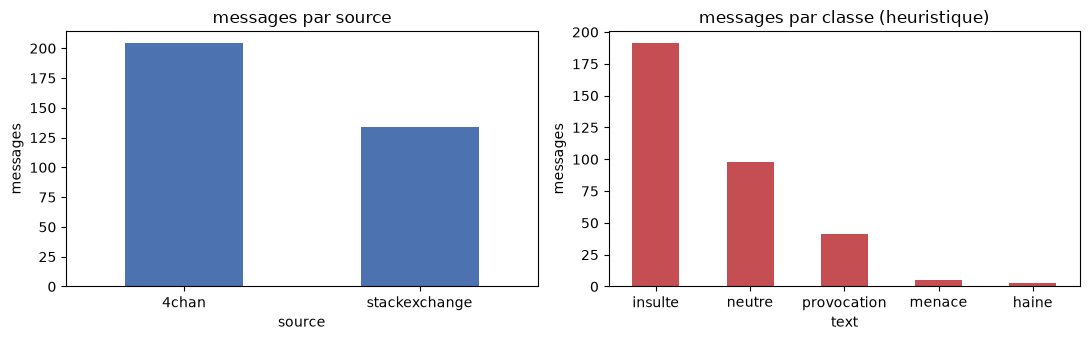

In [9]:
import matplotlib.pyplot as plt

labels = deduped["text"].map(dataset.classify)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
clean["source"].value_counts().plot.bar(ax=axes[0], title="messages par source", color="#4C72B0")
labels.value_counts().plot.bar(ax=axes[1], title="messages par classe (heuristique)", color="#C44E52")
for ax in axes:
    ax.set_ylabel("messages")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

make sure to keep your refrigerator firmware up to date | 4chan


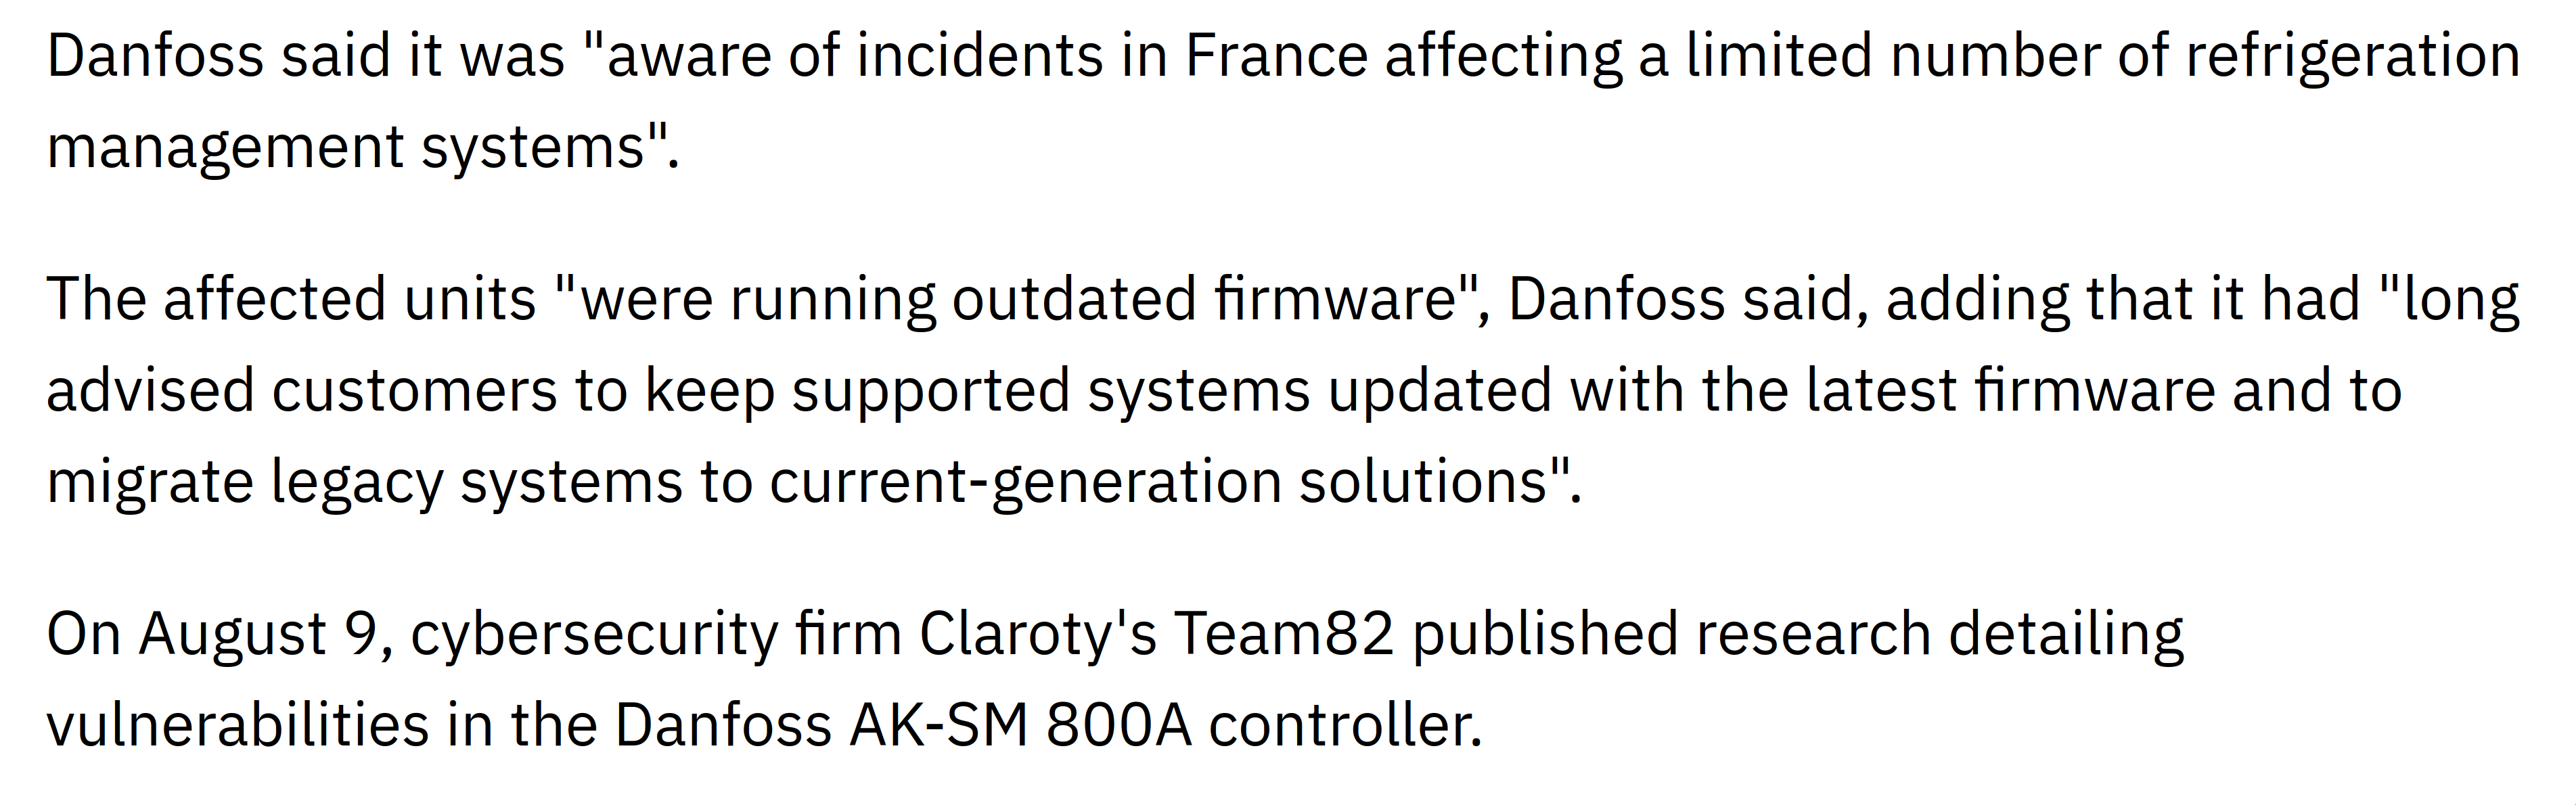

>>110052304 make sure to wait for other suckers to update first. | 4chan


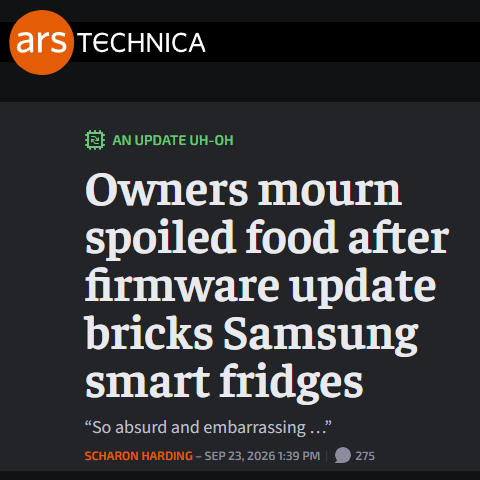

>>110052304 >be clever >change password every day >set it to the today's date | 4chan


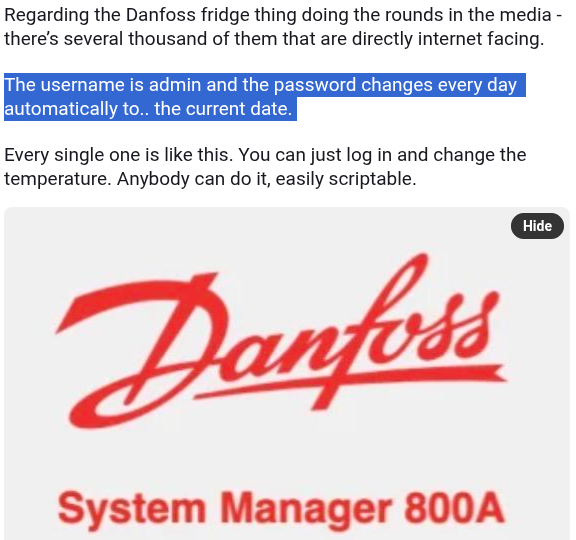

In [10]:
for _, row in images_locales.head(3).iterrows():
    chemin = config.DATA_DIR / row["media"]
    print(" ".join(row["clean_text"].split())[:90], "|", row["source"])
    display(Image(filename=str(chemin), width=220))

## Partie 6 — Suivi et traçabilité (MLOps)

Chaque exécution de `pipeline.run_pipeline` peut être journalisée dans MLflow
(`tracking.log_run`) : paramètres de collecte, métriques du corpus et artefacts
(CSV, mini-rapport, README). Les jeux de données sont en plus versionnés par DVC.

In [11]:
import mlflow

mlflow.set_tracking_uri(config.MLFLOW_TRACKING_URI)
runs = mlflow.search_runs(experiment_names=[config.MLFLOW_EXPERIMENT])
colonnes = [c for c in runs.columns if c.startswith(("params.", "metrics.", "tags.mlflow.runName"))]
display(runs[colonnes].head())

C:\Users\ellou\OneDrive\Desktop\Info\MLOps\TP2Ex1\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,metrics.nb_stackexchange,metrics.nb_raw,metrics.nb_images,metrics.pct_insulte,metrics.mean_length,metrics.pct_menace,metrics.pct_haine,metrics.lexical_diversity,metrics.pct_neutre,metrics.nb_4chan,...,metrics.nb_clean,params.nb_keywords,params.sources,params.max_images,params.sites_stackexchange,params.collection_date,params.boards_4chan,params.keywords_4chan,params.keywords,tags.mlflow.runName
0,134.0,339.0,20.0,56.5,444.6,1.5,0.9,0.268,29.0,204.0,...,338.0,47,"4chan, stackexchange",20,"stackoverflow, gaming",2026-10-13 10:27:52 UTC,"g, v",12 threads/board,"idiot, stupid, moron, loser, ugly, dumb, brainlet, smoothbrain, worthless, pathetic, trash, garbage, useless, clown, noob, fool, shill, kill yourself, kys, ...",collect_2026-10-13


### Conclusion

Corpus multimodal constitué de messages publics (4chan + Stack Exchange),
anonymisés, dédoublonnés et nettoyés, avec images stockées localement.
Limites : l'étiquetage des classes est une heuristique par mots-clés, la
classe `haine` est rare, et Stack Exchange apporte du bruit (code, citations).
Détail complet dans `../REPORT.md` et `../README.md`.